简单输运方程的求解:一维匀速对流方程

$$
\frac{\partial q}{\partial t} + c \frac{\partial q}{\partial x} = 0
$$
沿特征线 $x-ct=\text{常数}$，场值保持不变：
$$
\boxed{q(x,t)=q_0(x-ct).}
$$
采用周期边界 $q(0,t)=q(L,t)$，相当于波形从右边离开后从左边重新进入。
选取长度为 $L=1$ 的周期区间，光滑初值是一段窄的周期高斯脉冲

In [1]:
import math
import time
from functools import partial

import numpy as np
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
from jax import lax

# 先使用 CPU 上适合数值实验的双精度，减少舍入误差干扰。
jax.config.update("jax_enable_x64", True)

print("JAX version:", jax.__version__)
print("Available devices:", jax.devices())

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


JAX version: 0.12.0.1
Available devices: [CpuDevice(id=0)]


周期边界的设置
$$
q_{-1}=q_{N-1},\qquad q_N=q_0.
$$

In [2]:
a = jnp.array([10, 20, 30, 40])
print("Original :", np.asarray(a))
print("Left nbr:", np.asarray(jnp.roll(a, 1)))
print("Right nbr:", np.asarray(jnp.roll(a, -1)))
assert np.array_equal(np.asarray(jnp.roll(a, 1)), np.array([40, 10, 20, 30]))

Original : [10 20 30 40]
Left nbr: [40 10 20 30]
Right nbr: [20 30 40 10]


初始化边界：周期高斯脉冲

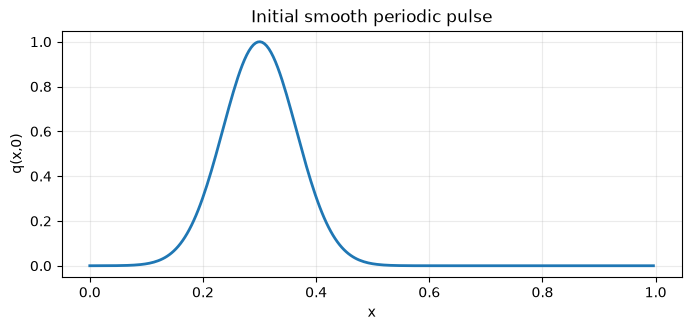

In [3]:
L = 1.0
N = 256
c = 1.0                  # 本课先研究 c > 0
x0 = 0.30
sigma = 0.065

dx = L / N
x = jnp.linspace(0.0, L, N, endpoint=False)

def periodic_distance(x, center, length=1.0):
    return jnp.mod(x - center + length / 2, length) - length / 2

def gaussian(x, center, sigma, length=1.0):
    distance = periodic_distance(x, center, length)
    return jnp.exp(-0.5 * (distance / sigma) ** 2)

q0 = gaussian(x, x0, sigma, L)

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(np.asarray(x), np.asarray(q0), lw=2)
ax.set(xlabel="x", ylabel="q(x,0)", title="Initial smooth periodic pulse")
ax.grid(alpha=0.25)
plt.show()

空间差分：

迎风格式：按照信息（波形）的传播方向，用上游的点进行差分，近似空间导数

假设 $c>0$，信息从左向右传播。用**左侧**节点构造一阶迎风导数：

$$
\left.\frac{\partial q}{\partial x}\right|_j
\approx\frac{q_j-q_{j-1}}{\Delta x}.
$$

时间方向用显式欧拉：

$$
\frac{q_j^{n+1}-q_j^n}{\Delta t}
+c\frac{q_j^n-q_{j-1}^n}{\Delta x}=0.
$$

于是
$$
\begin{aligned}
q_j^{n+1}
&=q_j^n-c\Delta t\frac{q_j^n-q_{j-1}^n}{\Delta x}\\
&=q_j^n-C(q_j^n-q_{j-1}^n).
\end{aligned}
$$

$C=c\Delta t/\Delta x$ 是**Courant数**，它是一个无量纲数，表示信息在一个时间步长内传播的距离与网格间距的比值。Courant数越大，信息传播的速度越快。

稳定条件为 $C \leq 1$。

各种格式的代码构成，采用roll，向下滚动一位，这样正好是迎风格式对其，在周期条件下。

In [4]:
def step_upwind(q, C):
    """c > 0, 1D periodic upwind + forward Euler."""
    left = jnp.roll(q, 1)
    return q - C * (q - left)

def step_central(q, C):
    """Central spatial derivative + forward Euler (unstable for advection)."""
    left = jnp.roll(q, 1)
    right = jnp.roll(q, -1)
    return q - 0.5 * C * (right - left)

def step_lax_wendroff(q, C):
    """Second-order Lax–Wendroff for constant-speed advection."""
    left = jnp.roll(q, 1)
    right = jnp.roll(q, -1)
    return q - 0.5 * C * (right - left) + 0.5 * C**2 * (right - 2 * q + left)

# 小型单步检查：周期网格下，各格式都会守恒离散和。
test = jnp.array([0.2, 0.5, 0.7, 0.1])
for name, f in [('upwind', step_upwind), ('central', step_central), ('LW', step_lax_wendroff)]:
    result = f(test, 0.6)
    assert np.isclose(float(jnp.sum(test)), float(jnp.sum(result)))
    print(f"{name:14s}: {np.asarray(result)}")

upwind        : [0.14 0.32 0.58 0.46]
central       : [0.08 0.35 0.82 0.25]
LW            : [0.116 0.332 0.676 0.376]


In [5]:
@partial(jax.jit, static_argnames=("nsteps", "scheme"))
def evolve_1d(q_initial, C, nsteps, scheme="upwind"):
    if scheme == "upwind":
        step_fn = step_upwind
    elif scheme == "central":
        step_fn = step_central
    elif scheme == "lax_wendroff":
        step_fn = step_lax_wendroff
    else:
        raise ValueError(f"Unknown scheme: {scheme}")
    return lax.fori_loop(0, nsteps, lambda _, q: step_fn(q, C), q_initial)

def step_count_for_target(T, dx, speed, target_cfl=0.65):
    nsteps = max(1, math.ceil(T * abs(speed) / (target_cfl * dx)))
    dt = T / nsteps
    return nsteps, dt, abs(speed) * dt / dx

实验运行，高斯脉动的移动

N=256, dx=0.003906, T=0.8, nsteps=316, dt=0.002532, C=0.6481


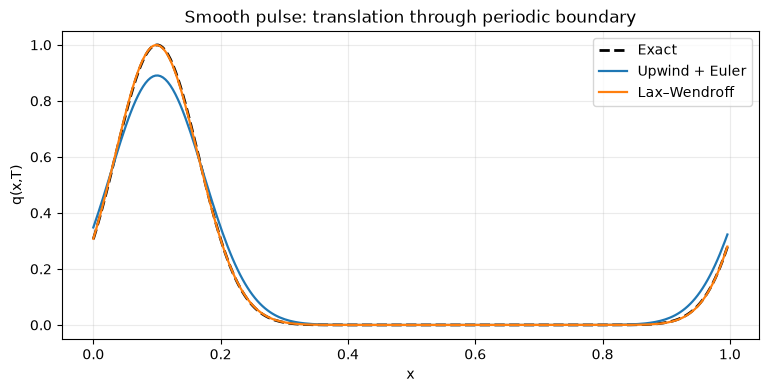

In [6]:
T = 0.80
nsteps, dt, C = step_count_for_target(T, dx, c, target_cfl=0.65)
q_exact = gaussian(x, x0 + c*T, sigma, L)
q_upwind = evolve_1d(q0, C, nsteps, "upwind")
q_lw = evolve_1d(q0, C, nsteps, "lax_wendroff")

print(f"N={N}, dx={dx:.6f}, T={T}, nsteps={nsteps}, dt={dt:.6f}, C={C:.4f}")
assert 0 < C <= 1
assert np.all(np.isfinite(np.asarray(q_upwind)))
assert np.all(np.isfinite(np.asarray(q_lw)))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(np.asarray(x), np.asarray(q_exact), 'k--', lw=2, label='Exact')
ax.plot(np.asarray(x), np.asarray(q_upwind), lw=1.6, label='Upwind + Euler')
ax.plot(np.asarray(x), np.asarray(q_lw), lw=1.6, label='Lax–Wendroff')
ax.set(xlabel='x', ylabel='q(x,T)', title='Smooth pulse: translation through periodic boundary')
ax.legend()
ax.grid(alpha=0.25)
plt.show()

In [7]:
def diagnostics(q_num, q_ref, q_start, dx):
    diff = q_num - q_ref
    return {
        'L1_error': float(jnp.sum(jnp.abs(diff)) * dx),
        'L2_error': float(jnp.sqrt(jnp.sum(diff**2) * dx)),
        'Linf_error': float(jnp.max(jnp.abs(diff))),
        'mass_change': float((jnp.sum(q_num) - jnp.sum(q_start)) * dx),
        'min': float(jnp.min(q_num)),
        'max': float(jnp.max(q_num)),
    }

for name, result in [('Upwind', q_upwind), ('Lax–Wendroff', q_lw)]:
    d = diagnostics(result, q_exact, q0, dx)
    print(f"{name:15s} L1={d['L1_error']:.6e}  L2={d['L2_error']:.6e}  "
          f"mass_change={d['mass_change']:+.2e}  max={d['max']:.6f}")

assert abs(diagnostics(q_upwind, q_exact, q0, dx)['mass_change']) < 1e-10
assert abs(diagnostics(q_lw, q_exact, q0, dx)['mass_change']) < 1e-10

Upwind          L1=1.821962e-02  L2=3.299797e-02  mass_change=+2.78e-17  max=0.890573
Lax–Wendroff    L1=1.055257e-03  L2=1.993395e-03  mass_change=+2.78e-17  max=0.999302


### 为什么迎风格式会使高斯峰变矮、变宽？

对于 $c>0$，迎风 + 显式欧拉的**修正方程**首要附加项为：

$$
\frac{\partial q}{\partial t}
+c\frac{\partial q}{\partial x}
=\underbrace{\frac{c\Delta x}{2}(1-C)}_{\nu_{\mathrm{num}}}
\frac{\partial^2q}{\partial x^2}+\text{高阶项}.
$$

也就是说，离散误差可以在主导阶上等效为一个**人为扩散项**，扩散系数 $\nu_{\mathrm{num}}=c\Delta x(1-C)/2$。

这并非真实流体的黏性，而是数值格式引入的**数值耗散**。如果将来模拟圆柱涡街时数值耗散过大，尾涡可能被人为削弱。

> 该修正方程是光滑解、常系数、固定 Courant 数条件下的局部渐近解释，不应把它当成所有非线性 CFD 求解器的通用黏性系数。

中心差分+显示欧拉不稳定实验
这种情况下，中心差分会不断方法微弱高频信号，导致数值解发散。

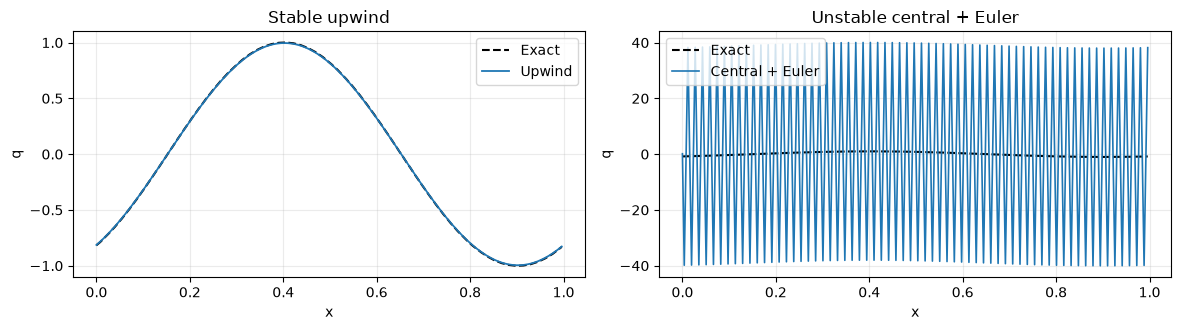

Central max |q|: 40.040720785102884


In [8]:
C_test = 0.65
n_test = 60
q_noise = jnp.sin(2 * jnp.pi * x / L) + 0.001 * jnp.sin(2 * jnp.pi * (N // 4) * x / L)
q_center_bad = evolve_1d(q_noise, C_test, n_test, "central")
q_upwind_test = evolve_1d(q_noise, C_test, n_test, "upwind")
t_test = n_test * (C_test * dx / c)
q_noise_exact = jnp.sin(2*jnp.pi*(x - c*t_test)/L) + 0.001*jnp.sin(2*jnp.pi*(N//4)*(x-c*t_test)/L)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
axes[0].plot(np.asarray(x), np.asarray(q_noise_exact), 'k--', label='Exact')
axes[0].plot(np.asarray(x), np.asarray(q_upwind_test), label='Upwind', lw=1.3)
axes[0].set(title='Stable upwind', xlabel='x', ylabel='q')
axes[1].plot(np.asarray(x), np.asarray(q_noise_exact), 'k--', label='Exact')
axes[1].plot(np.asarray(x), np.asarray(q_center_bad), label='Central + Euler', lw=1.2)
axes[1].set(title='Unstable central + Euler', xlabel='x', ylabel='q')
for a in axes:
    a.legend()
    a.grid(alpha=0.25)
plt.tight_layout()
plt.show()
print('Central max |q|:', float(jnp.max(jnp.abs(q_center_bad))))
assert float(jnp.max(jnp.abs(q_center_bad))) > 2.0

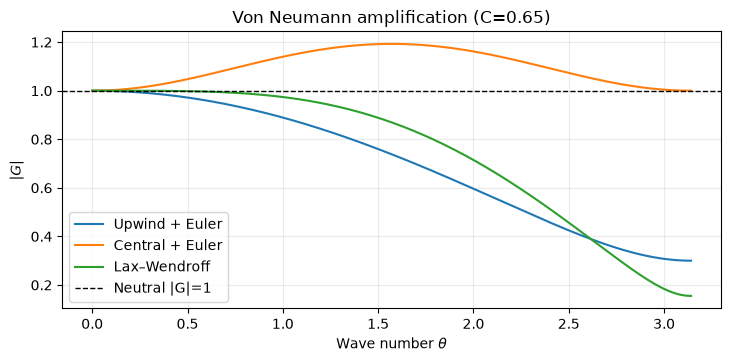

In [9]:
theta = np.linspace(0, np.pi, 400)
C_plot = 0.65
G_up = 1 - C_plot * (1 - np.exp(-1j*theta))
G_center = 1 - 1j*C_plot*np.sin(theta)
G_lw = 1 - 1j*C_plot*np.sin(theta) + C_plot**2*(np.cos(theta)-1)
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.plot(theta, abs(G_up), label='Upwind + Euler')
ax.plot(theta, abs(G_center), label='Central + Euler')
ax.plot(theta, abs(G_lw), label='Lax–Wendroff')
ax.axhline(1.0, color='black', linestyle='--', linewidth=1, label='Neutral |G|=1')
ax.set(xlabel=r'Wave number $\theta$', ylabel=r'$|G|$', title='Von Neumann amplification (C=0.65)')
ax.grid(alpha=0.25)
ax.legend()
plt.show()
assert np.max(np.abs(G_up)) <= 1 + 1e-12
assert np.max(np.abs(G_lw)) <= 1 + 1e-12
assert np.max(np.abs(G_center)) > 1

实验三：间断问题，数值振荡
将光滑高斯脉冲改为周期方波
$$
q_0(x)=\begin{cases}
1, & |d_L(x,x_0)|<w/2,\\
0, & \text{其他}.
\end{cases}
$$

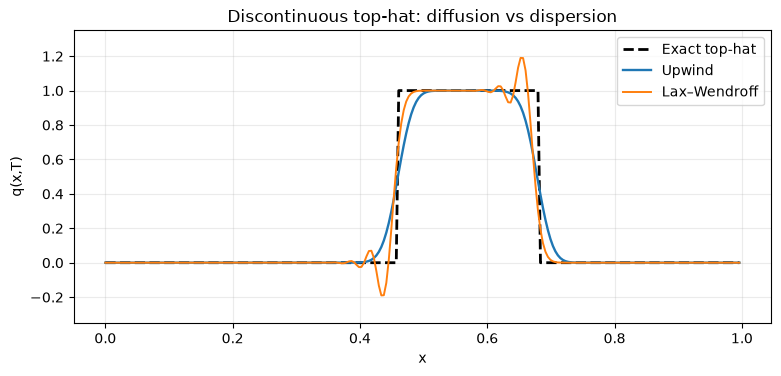

Upwind range : [0.0000, 1.0000]
LW range     : [-0.1900, 1.1900]


In [10]:
width = 0.22
q_square = jnp.where(jnp.abs(periodic_distance(x, x0, L)) < width/2, 1.0, 0.0)
T_square = 0.27
steps_square, dt_square, C_square = step_count_for_target(T_square, dx, c, 0.65)
up_square = evolve_1d(q_square, C_square, steps_square, 'upwind')
lw_square = evolve_1d(q_square, C_square, steps_square, 'lax_wendroff')
exact_square = jnp.where(jnp.abs(periodic_distance(x, x0+c*T_square, L)) < width/2, 1.0, 0.0)

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(np.asarray(x), np.asarray(exact_square), 'k--', lw=2, label='Exact top-hat')
ax.plot(np.asarray(x), np.asarray(up_square), label='Upwind', lw=1.7)
ax.plot(np.asarray(x), np.asarray(lw_square), label='Lax–Wendroff', lw=1.4)
ax.set(xlabel='x', ylabel='q(x,T)', title='Discontinuous top-hat: diffusion vs dispersion', ylim=(-0.35, 1.35))
ax.legend()
ax.grid(alpha=0.25)
plt.show()
print(f"Upwind range : [{float(jnp.min(up_square)):.4f}, {float(jnp.max(up_square)):.4f}]")
print(f"LW range     : [{float(jnp.min(lw_square)):.4f}, {float(jnp.max(lw_square)):.4f}]")
assert float(jnp.min(up_square)) >= -1e-12
assert float(jnp.max(up_square)) <= 1 + 1e-12
assert float(jnp.min(lw_square)) < -1e-3 or float(jnp.max(lw_square)) > 1.001

由一维拓展到二维
二维常速度标量对流方程：
$$
\frac{\partial q}{\partial t} + c_x \frac{\partial q}{\partial x} + c_y \frac{\partial q}{\partial y} = 0
$$

二维一阶迎风+显式欧拉：
$$
q_{i,j}^{n+1}=q_{i,j}^n-C_x(q_{i,j}^n-q_{i-1,j}^n)-C_y(q_{i,j}^n-q_{i,j-1}^n)
$$

对于这套线性方法，稳定（也保持单调性）的条件是：

$$
\boxed{C_x+C_y\le1.}
$$

In [16]:
test1 = jnp.array([[0.2, 0.5, 0.7, 0.1],
                   [0.3, 0.6, 0.8, 0.2],
                   [0.4, 0.7, 0.9, 0.3]])
test1_left = jnp.roll(test1, 1, axis=0)
test1_right = jnp.roll(test1, -1, axis=1)
print("Original:\n", np.asarray(test1))
print("Left nbr:\n", np.asarray(test1_left))
print("Right nbr:\n", np.asarray(test1_right))

Original:
 [[0.2 0.5 0.7 0.1]
 [0.3 0.6 0.8 0.2]
 [0.4 0.7 0.9 0.3]]
Left nbr:
 [[0.4 0.7 0.9 0.3]
 [0.2 0.5 0.7 0.1]
 [0.3 0.6 0.8 0.2]]
Right nbr:
 [[0.5 0.7 0.1 0.2]
 [0.6 0.8 0.2 0.3]
 [0.7 0.9 0.3 0.4]]


这里axis=0表示沿着行方向滚动，axis=1表示沿着列方向滚动。也就是二维情况下的按照x方向计算，还是按照y方向计算的区别

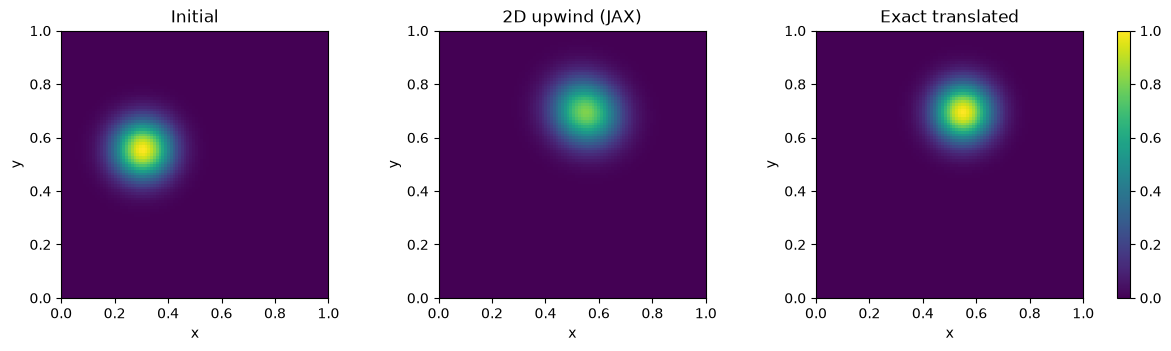

2D: Cx=0.3794, Cy=0.2168, Cx+Cy=0.5961
2D: mass difference=+6.939e-18; L2 error=1.975314e-02


In [11]:
@jax.jit
def step_upwind_2d(q, Cx, Cy):
    # First array axis represents x; second represents y.
    left = jnp.roll(q, 1, axis=0)
    bottom = jnp.roll(q, 1, axis=1)
    return q - Cx * (q - left) - Cy * (q - bottom)

@partial(jax.jit, static_argnames=("nsteps",))
def evolve_2d(q_initial, Cx, Cy, nsteps):
    return lax.fori_loop(
        0, nsteps, lambda _, q: step_upwind_2d(q, Cx, Cy), q_initial
    )

N2 = 96
Lx = Ly = 1.0
dx2 = Lx / N2
dy2 = Ly / N2
x2 = jnp.linspace(0.0, Lx, N2, endpoint=False)
y2 = jnp.linspace(0.0, Ly, N2, endpoint=False)
X2, Y2 = jnp.meshgrid(x2, y2, indexing='ij')
cx, cy = 0.7, 0.4
T2 = 0.35
# 保守地选择 Cx+Cy <= 0.60
nsteps2 = math.ceil(T2 * (cx/dx2 + cy/dy2) / 0.60)
dt2 = T2 / nsteps2
Cx, Cy = cx*dt2/dx2, cy*dt2/dy2
assert Cx + Cy <= 0.60 + 1e-12

center_x, center_y = 0.30, 0.55
sig2 = 0.075
q2_0 = gaussian(X2, center_x, sig2, Lx) * gaussian(Y2, center_y, sig2, Ly)
q2_exact = (gaussian(X2, center_x + cx*T2, sig2, Lx)
            * gaussian(Y2, center_y + cy*T2, sig2, Ly))
q2_final = evolve_2d(q2_0, Cx, Cy, nsteps2)

fig, axes = plt.subplots(1, 3, figsize=(12.0, 3.4), constrained_layout=True)
for ax, data, label in zip(axes,
                           (q2_0, q2_final, q2_exact),
                           ('Initial', '2D upwind (JAX)', 'Exact translated')):
    im = ax.imshow(np.asarray(data).T, origin='lower', extent=[0,1,0,1],
                   vmin=0, vmax=1, cmap='viridis', interpolation='nearest')
    ax.set(title=label, xlabel='x', ylabel='y', aspect='equal')
fig.colorbar(im, ax=axes, fraction=0.023, pad=0.02)
plt.savefig('JAX_CFD_Lesson_02_preview.png', dpi=160, bbox_inches='tight')
plt.show()

mass2_initial = float(jnp.sum(q2_0) * dx2 * dy2)
mass2_final = float(jnp.sum(q2_final) * dx2 * dy2)
err2 = float(jnp.sqrt(jnp.sum((q2_final - q2_exact)**2) * dx2 * dy2))
print(f"2D: Cx={Cx:.4f}, Cy={Cy:.4f}, Cx+Cy={Cx+Cy:.4f}")
print(f"2D: mass difference={mass2_final-mass2_initial:+.3e}; L2 error={err2:.6e}")
assert abs(mass2_final-mass2_initial) < 1e-10
assert np.isfinite(err2) and err2 > 0